# 6장 단일 캡슐의 정적 지각 추론 (실습)

능동 추론 캡슐 하나(숨은 상태 하나, 감각 하나, 사전 하나)가 자유 에너지의 경사 하강만으로 Hydar 의 깊이를 추론하는지 확인한다. 일반화 좌표는 없고, 물은 잔잔하며, Hydar 는 아직 움직이지 못한다.

1. 생성 과정: 깊이에 따른 수온 곡선
2. 캡슐 버전 0.1 과 시뮬레이션 루프
3. 사전과 감각이 어긋날 때 믿음은 어디에 자리 잡는가, 해석해와 맞는가
4. 감각과 사전 가운데 무엇을 더 믿는가 — 두 분산의 비
5. 백색 잡음과 유색 잡음 아래에서
6. 분산의 절대 크기와 학습률은 수렴 속도를 어떻게 바꾸는가
7. 자유 에너지가 음수가 되는 경우
8. 단순한 선형 생성 모델로도 되는가

마지막으로 학습률이 이산 시간의 한계를 넘으면 무엇이 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz
from scipy.optimize import brentq

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt = 0.005                 # 적분 간격: 뉴런이 1 초에 200 번 갱신한다
T = 5.0
t = np.arange(0, T + dt / 2, dt)
N = t.size
print("시간 점", N, "개:", t[:3], "...", t[-2:])

시간 점 1001 개: [0.    0.005 0.01 ] ... [4.995 5.   ]


## 1. 생성 과정 — 깊이와 수온

Hydar 의 바깥 세계다. 물이 잔잔하므로 깊이는 처음 자리에 머문다(x = v + w). 수온은 깊이에 따라 시그모이드 꼴로 떨어진다.

g_gp(x) = 25 − 16 / (1 + e^(5 − x/5)),  g′_gp(x) = −(16/5) e^(5 − x/5) / (1 + e^(5 − x/5))²

In [2]:
def g_gp(x):
    """생성 과정의 감각 사상: 깊이 x(cm) 에서의 수온(°C)."""
    return 25 - 16 / (1 + np.exp(5 - x / 5))

def dg_gp(x):
    """감각 사상의 x 에 대한 도함수."""
    e = np.exp(5 - x / 5)
    return -16 / 5 * e / (1 + e)**2

for depth in [0, 20, 25, 30, 50]:
    print(f"깊이 {depth:2d} cm   수온 {g_gp(depth):6.2f} °C   기울기 {dg_gp(depth):+.3f} °C/cm")

깊이  0 cm   수온  24.89 °C   기울기 -0.021 °C/cm
깊이 20 cm   수온  20.70 °C   기울기 -0.629 °C/cm
깊이 25 cm   수온  17.00 °C   기울기 -0.800 °C/cm
깊이 30 cm   수온  13.30 °C   기울기 -0.629 °C/cm
깊이 50 cm   수온   9.11 °C   기울기 -0.021 °C/cm


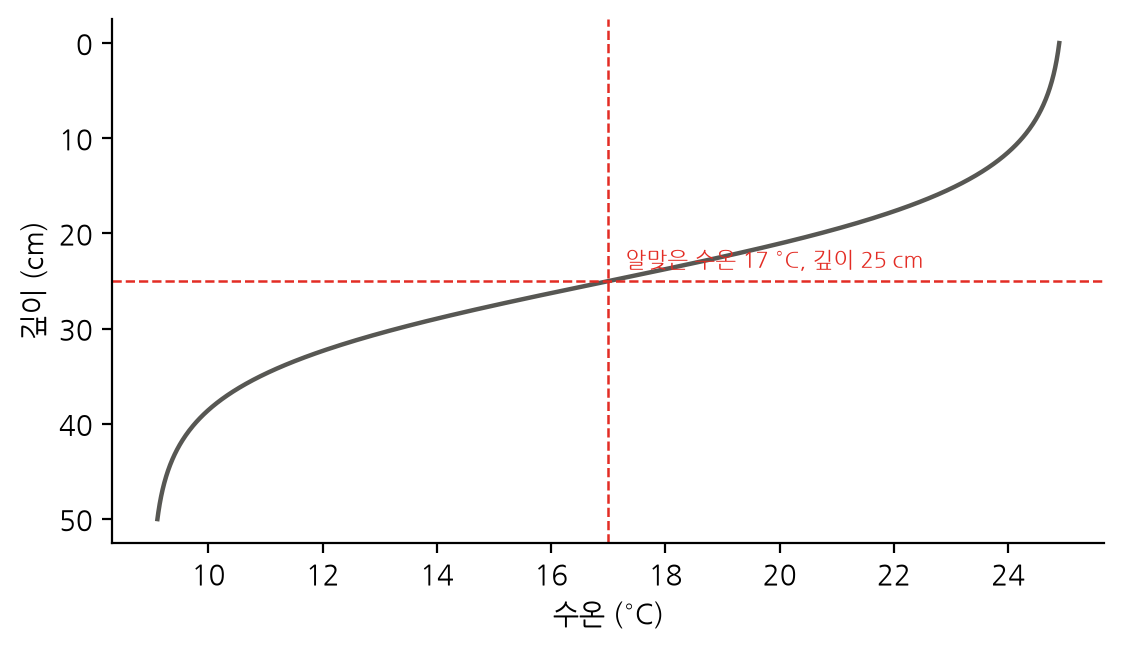

In [3]:
xs = np.linspace(0, 50, 501)
plt.figure(figsize=(6.4, 3.4))
plt.plot(g_gp(xs), xs, color="#575753", lw=1.6)
plt.gca().invert_yaxis()
plt.axvline(17, color="#E32C24", ls="--", lw=0.9)
plt.axhline(25, color="#E32C24", ls="--", lw=0.9)
plt.text(17.3, 23.5, "알맞은 수온 17 °C, 깊이 25 cm", color="#E32C24", fontsize=8)
plt.xlabel("수온 (°C)")
plt.ylabel("깊이 (cm)")
plt.show()

## 2. 전진 오일러 — 가장 단순한 적분

경사 하강을 미분 방정식 μ̇ = −α ∂F/∂μ 로 쓰면, 컴퓨터에서는 작은 시간 간격 Δt 마다 μ(t+Δt) = μ(t) + Δt·μ̇ 로 한 걸음씩 옮긴다. 도함수 2x 를 따라 걸어 x² 을 되살리는지 본다.

In [4]:
xg = np.arange(-2, 2, 0.001)
I = np.zeros(xg.size)
I[0] = 4.0
for i in range(1, xg.size):
    I[i] = I[i - 1] + 0.001 * 2 * xg[i - 1]       # 기울기 2x 를 따라 한 걸음
print(f"최대 오차 |I − x²| = {np.abs(I - xg**2).max():.4f}  (간격 0.001)")

최대 오차 |I − x²| = 0.0040  (간격 0.001)


## 3. 유색 잡음과 캡슐 버전 0.1

makeNoise 는 2장의 그 함수다. 캡슐은 예측 오차 둘을 계산하고, 자유 에너지의 기울기를 구해, 전진 오일러로 믿음 μ_x 를 한 걸음 옮긴다.

- ε_x = μ_x − f(μ_x, μ_v) = μ_x − μ_v,   ε_y = y − g(μ_x)
- ∂F/∂μ_x = ε_x/σ_w² − g′(μ_x) ε_y/σ_z²
- F = ½ (ε_x²/σ_w² + ε_y²/σ_z² + ln σ_w²σ_z²)

In [5]:
def makeNoise(C, s2, t):
    """공분산 C, 매끄러움 s2 인 유색 잡음."""
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))


class ai_capsule:
    """숨은 상태 하나, 감각 하나, 사전 하나를 맡는 뉴런 묶음 (버전 0.1)."""

    def __init__(self, dt, mu_v, Sigma_w, Sigma_z, a_mu, g=g_gp, dg=dg_gp):
        self.dt = dt
        self.mu_x = mu_v            # 믿음은 사전에서 출발한다
        self.Sigma_w = Sigma_w      # 숨은 상태(사전)의 분산
        self.Sigma_z = Sigma_z      # 감각의 분산
        self.alpha_mu = a_mu        # 학습률
        self.g, self.dg = g, dg     # 생성 모델의 감각 사상과 그 도함수
        self.F = self.eps_x = self.eps_y = 0.0

    def f(self, x, v):
        """운동 방정식: 정적인 세계이므로 깊이는 사전 믿음 그대로다."""
        return v

    def inference_step(self, mu_v, y):
        self.eps_x = self.mu_x - self.f(self.mu_x, mu_v)          # 사전 예측 오차
        self.eps_y = y - self.g(self.mu_x)                        # 감각 예측 오차
        dFdmu_x = self.eps_x / self.Sigma_w - self.dg(self.mu_x) * self.eps_y / self.Sigma_z
        self.mu_x += self.dt * (0 - self.alpha_mu * dFdmu_x)      # Dμ = 0: 일반화 좌표 없음
        self.F = 0.5 * (self.eps_x**2 / self.Sigma_w + self.eps_y**2 / self.Sigma_z
                        + np.log(self.Sigma_w * self.Sigma_z))
        return self.F, self.mu_x, self.g(self.mu_x)


cap = ai_capsule(dt, 25.0, 1.0, 1.0, 1.0)
F0, m0, gy0 = cap.inference_step(25.0, g_gp(30.0))
print(f"첫 걸음: F = {F0:.3f}, μx = {m0:.4f}, g(μx) = {gy0:.3f}")

첫 걸음: F = 6.834, μx = 25.0148, g(μx) = 16.988


In [6]:
def simulation(v, mu_v, Sigma_w, Sigma_z, noise="none", a_mu=1.0, g=g_gp, dg=dg_gp, seed=42):
    """정적인 Hydar 로 지각 추론을 돌린다. noise: 'none' | 'white' | 'smooth'."""
    F, mu_x, mu_y, x, y = (np.zeros(N) for _ in range(5))
    capsule = ai_capsule(dt, mu_v, Sigma_w, Sigma_z, a_mu, g, dg)
    rng = np.random.default_rng(seed)
    np.random.seed(seed)
    w = makeNoise(Sigma_w, 1 / 2000, t)[0]
    z = makeNoise(Sigma_z, 1 / 2000, t)[0]
    for i in range(1, N):
        if noise == "white":
            x[i] = v + rng.standard_normal() * np.sqrt(Sigma_w)
            y[i] = g_gp(x[i]) + rng.standard_normal() * np.sqrt(Sigma_z)
        elif noise == "smooth":
            x[i] = v + w[i]
            y[i] = g_gp(x[i]) + z[i]
        else:
            x[i] = v
            y[i] = g_gp(v)
        F[i], mu_x[i], mu_y[i] = capsule.inference_step(mu_v, y[i])
    return dict(F=F, mu_x=mu_x, mu_y=mu_y, x=x, y=y)


def plot_runs(runs, mu_v, logF=True):
    fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6.4, 5.2))
    colors = ["#E32C24", "#1f77b4", "#2ca02c"]
    for (label, r), c in zip(runs.items(), colors):
        ax[0].plot(t[1:], r["mu_x"][1:], color=c, label=label)
        ax[1].plot(t[1:], r["mu_y"][1:], color=c)
        (ax[2].semilogy if logF else ax[2].plot)(t[1:], r["F"][1:], color=c)
    r0 = next(iter(runs.values()))
    ax[0].plot(t[1:], r0["x"][1:], color="#575753", lw=0.8, label="실제 깊이")
    ax[1].plot(t[1:], r0["y"][1:], color="#575753", lw=0.8)
    ax[0].axhline(mu_v, color="#999999", ls=":", lw=0.9, label="사전 믿음")
    ax[1].axhline(g_gp(mu_v), color="#999999", ls=":", lw=0.9)
    ax[0].set_ylabel("깊이 μx"); ax[1].set_ylabel("수온 g(μx)"); ax[2].set_ylabel("자유 에너지")
    ax[2].set_xlabel("시간 (초)")
    ax[0].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    fig.tight_layout()
    plt.show()

print("simulation, plot_runs 준비 완료")

simulation, plot_runs 준비 완료


## 4. 실험 1 — 사전과 감각이 어긋날 때

Hydar 는 깊이 25 cm(수온 17 °C)에 있다고 믿지만 실제로는 30 cm 에 있어 수온이 약 13 °C 로 읽힌다. 두 분산이 모두 1 이다. 잡음은 넣지 않는다.

정상 상태에서는 ∂F/∂μ_x = 0 이다. 이 식의 근을 brentq 로 따로 구해 시뮬레이션과 비교한다.

In [7]:
v, mu_v = 30.0, 25.0
r1 = simulation(v, mu_v, 1.0, 1.0)

def fixed_point(mu_v, y, s_w, s_z, g=g_gp, dg=dg_gp):
    """∂F/∂μ = 0 의 근: 정상 상태의 믿음."""
    return brentq(lambda m: (m - mu_v) / s_w - dg(m) * (y - g(m)) / s_z, mu_v - 20, mu_v + 20)

mu_star = fixed_point(mu_v, g_gp(v), 1.0, 1.0)
for sec in [0.005, 0.5, 1, 2, 5]:
    k = int(round(sec / dt))
    print(f"t={sec:5.3f}s   μx={r1['mu_x'][k]:7.3f}   g(μx)={r1['mu_y'][k]:6.3f}   F={r1['F'][k]:7.3f}")
print(f"감각 수온 y = {g_gp(v):.3f}, 사전 수온 g(μv) = {g_gp(mu_v):.3f}")
print(f"해석해 μ* = {mu_star:.4f}   시뮬레이션 마지막 μx = {r1['mu_x'][-1]:.4f}")

t=0.005s   μx= 25.015   g(μx)=16.988   F=  6.834
t=0.500s   μx= 26.008   g(μx)=16.196   F=  4.702
t=1.000s   μx= 26.444   g(μx)=15.853   F=  4.295
t=2.000s   μx= 26.714   g(μx)=15.642   F=  4.204
t=5.000s   μx= 26.776   g(μx)=15.594   F=  4.201
감각 수온 y = 13.303, 사전 수온 g(μv) = 17.000
해석해 μ* = 26.7761   시뮬레이션 마지막 μx = 26.7756


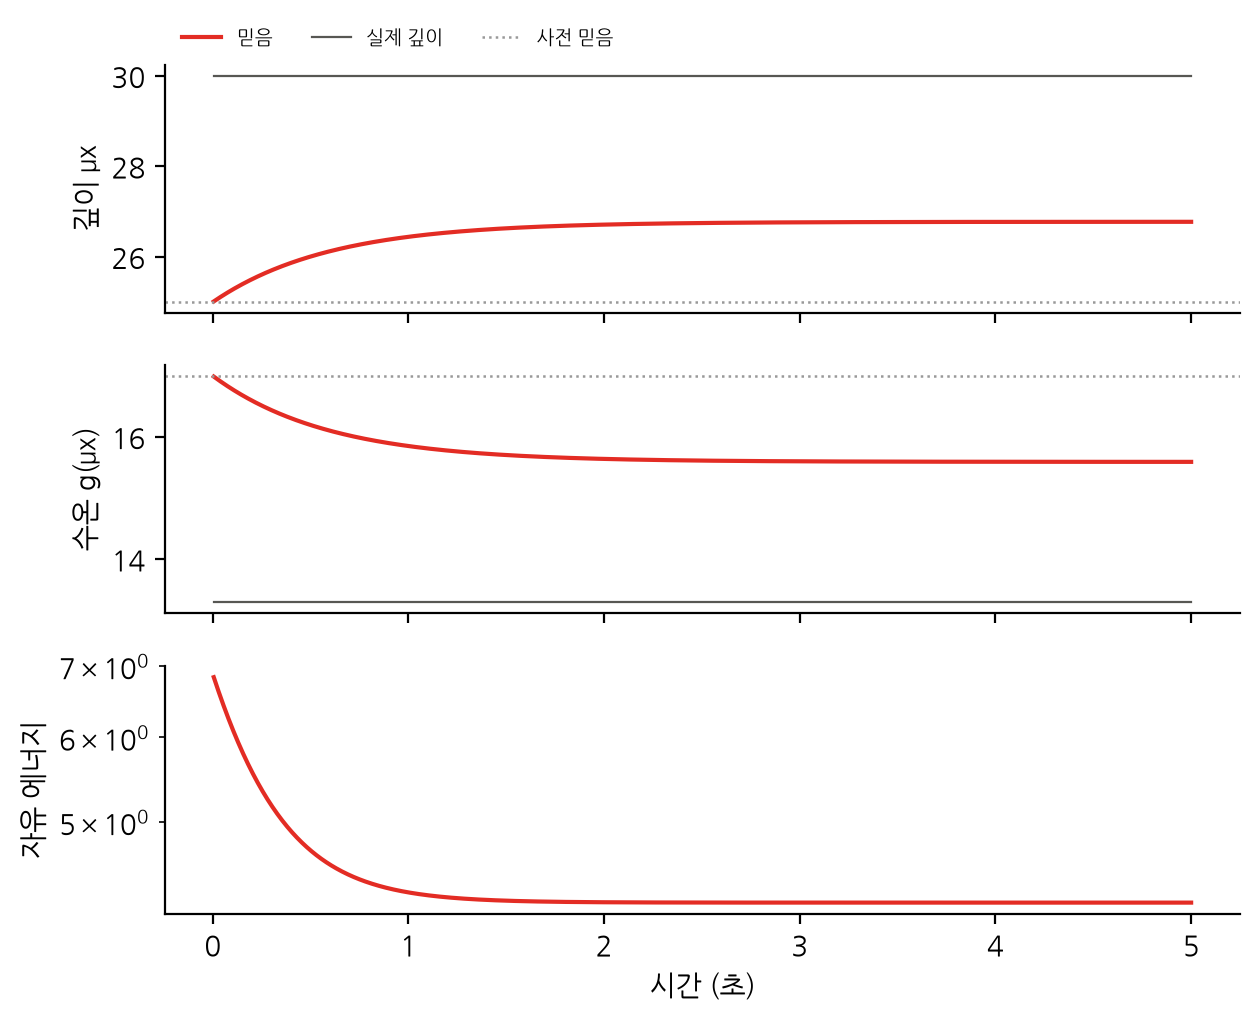

In [8]:
plot_runs({"믿음": r1}, mu_v)

## 5. 실험 2 — 예상한 대로 감각될 때

사전과 실제 깊이가 모두 25 cm 다.

In [9]:
r2 = simulation(25.0, 25.0, 1.0, 1.0)
print(f"마지막 μx = {r2['mu_x'][-1]:.4f},  F 의 최댓값 = {np.abs(r2['F'][1:]).max():.2e}")

마지막 μx = 25.0000,  F 의 최댓값 = 0.00e+00


## 6. 실험 3 — 감각을 믿을까, 사전을 믿을까

두 분산의 비를 바꾼다. σ_z² 가 작으면 감각을 믿고, σ_w² 가 작으면 사전(내부 모델)을 믿는다.

In [10]:
cases = {"균형 (1, 1)": (1.0, 1.0), "감각을 믿음 (1, 0.1)": (1.0, 0.1), "사전을 믿음 (0.1, 1)": (0.1, 1.0)}
r3 = {}
print("경우                     μx 최종    해석해    g(μx)")
for name, (s_w, s_z) in cases.items():
    r3[name] = simulation(v, mu_v, s_w, s_z)
    print(f"{name:20s}  {r3[name]['mu_x'][-1]:7.3f}   {fixed_point(mu_v, g_gp(v), s_w, s_z):7.3f}   {r3[name]['mu_y'][-1]:6.3f}")

경우                     μx 최종    해석해    g(μx)


균형 (1, 1)              26.776    26.776   15.594
감각을 믿음 (1, 0.1)        29.083    29.083   13.903


사전을 믿음 (0.1, 1)        25.278    25.278   16.778


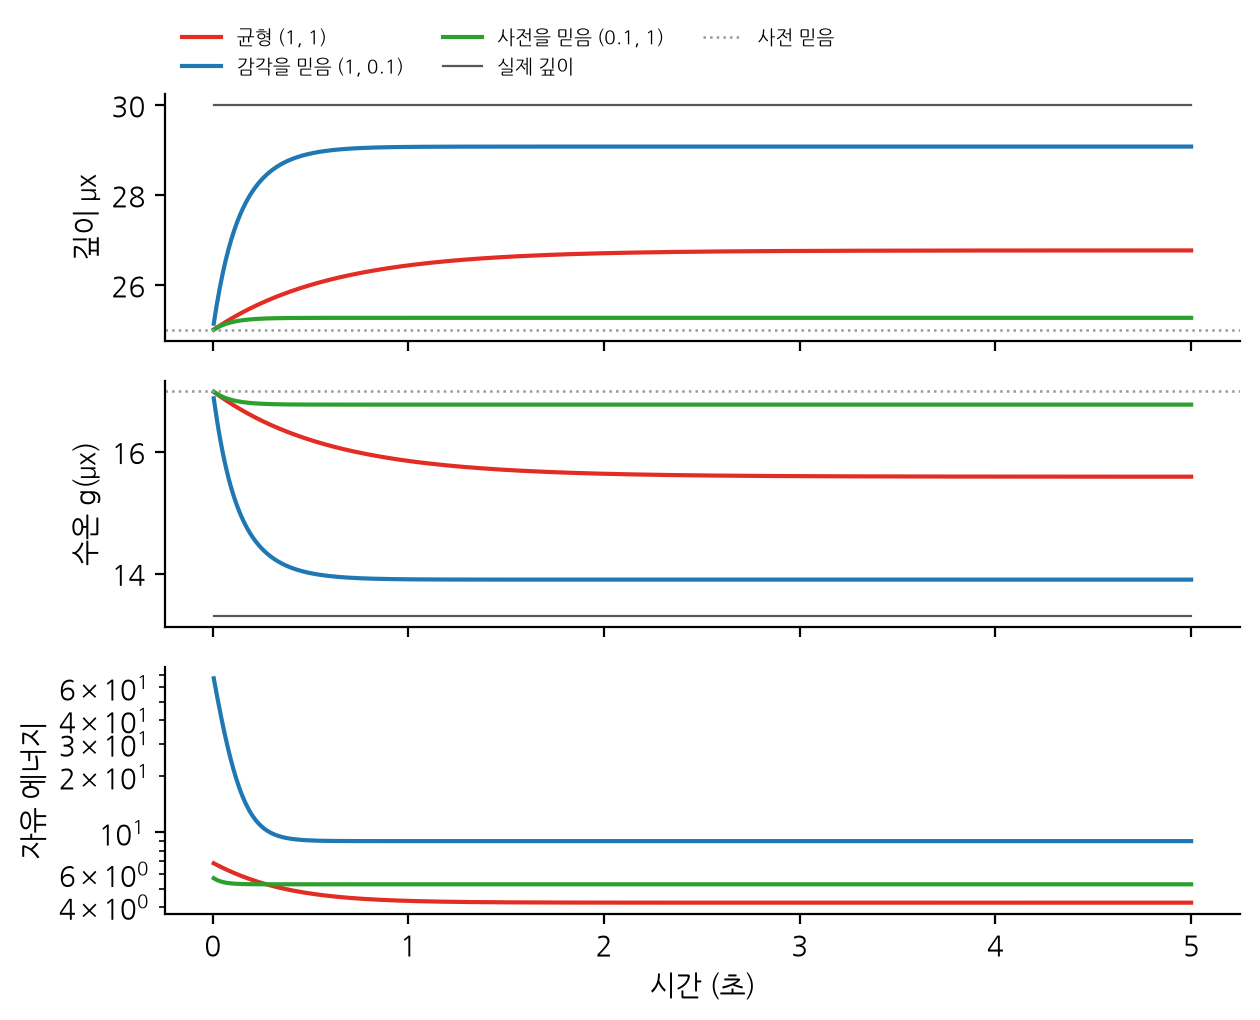

In [11]:
plot_runs(r3, mu_v)

## 7. 실험 4 — 백색 잡음과 유색 잡음

생성 과정에 실제 잡음을 넣는다. 백색 잡음은 분산 0.1, 유색 잡음은 분산 1 에 매끄러움 1/2000 이다. 마지막 2 초 동안 감각이 가리키는 깊이와 믿음이 얼마나 흔들리는지 비교한다.

In [12]:
def implied_depth(y):
    """수온 y 를 내는 깊이 (g_gp 의 역함수)."""
    return 5 * (5 - np.log(16 / (25 - y) - 1))

tail = t > 3
for name, (noise, s2) in {"백색 0.1": ("white", 0.1), "유색 1": ("smooth", 1.0)}.items():
    r = simulation(v, mu_v, s2, s2, noise=noise)
    yd = implied_depth(np.clip(r["y"][tail], 9.05, 24.95))
    print(f"{name:7s}  감각이 가리키는 깊이: 평균 {yd.mean():6.2f}, 표준편차 {yd.std():5.2f}   "
          f"믿음 μx: 평균 {r['mu_x'][tail].mean():6.2f}, 표준편차 {r['mu_x'][tail].std():5.3f}")

백색 0.1   감각이 가리키는 깊이: 평균  30.01, 표준편차  0.64   믿음 μx: 평균  26.77, 표준편차 0.037
유색 1     감각이 가리키는 깊이: 평균  29.95, 표준편차  1.81   믿음 μx: 평균  26.71, 표준편차 0.152


## 8. 실험 5 — 분산의 크기와 학습률

두 분산을 같은 비율로 키우거나 줄이면 정상 상태의 믿음(분산의 비로 정해진다)은 그대로이고 수렴 속도만 바뀐다. 학습률도 같은 일을 한다. 최종값의 1 % 안으로 들어오는 시간을 잰다.

In [13]:
def settle_time(mu, tol=0.01):
    """μ 가 최종값과의 거리가 처음 거리의 tol 배 안으로 들어온 시각."""
    gap = np.abs(mu[1:] - mu[-1])
    out = np.where(gap > tol * gap[0])[0]
    return t[1:][out[-1] + 1] if out.size else t[1]

print("두 분산     학습률   μx 최종    1% 수렴 시간")
for s2, a in [(10, 1), (1, 1), (0.1, 1), (1, 10), (1, 100)]:
    r = simulation(v, mu_v, s2, s2, a_mu=a)
    print(f"{s2:6.1f}     {a:5d}    {r['mu_x'][-1]:7.3f}    {settle_time(r['mu_x']):7.3f}s")
print(f"해석해 μ* = {fixed_point(mu_v, g_gp(v), 1.0, 1.0):.3f}  (두 분산의 비가 같으면 모두 같은 값)")

두 분산     학습률   μx 최종    1% 수렴 시간


  10.0         1     26.006      4.925s


   1.0         1     26.776      2.745s
   0.1         1     26.776      0.270s


   1.0        10     26.776      0.270s
   1.0       100     26.776      0.020s
해석해 μ* = 26.776  (두 분산의 비가 같으면 모두 같은 값)


## 9. 실험 6 — 자유 에너지가 음수가 된다

사전이 실제 깊이에 아주 가깝고(29.9 와 30) 분산이 작으면 ½ ln σ_w²σ_z² 항이 음수가 되어 자유 에너지 전체가 음수가 된다.

In [14]:
print("분산      F 최종        ½ ln(σw²σz²)")
for s2 in [1.0, 0.1, 0.01]:
    r = simulation(30.0, 29.9, s2, s2, noise="smooth")
    print(f"{s2:5.2f}   {r['F'][-1]:10.4f}     {0.5 * np.log(s2 * s2):8.4f}")

분산      F 최종        ½ ln(σw²σz²)
 1.00       0.8038       0.0000
 0.10      -1.0240      -2.3026
 0.01      -3.3548      -4.6052


## 10. 실험 7 — 단순한 선형 생성 모델

Hydar 가 정확한 시그모이드 대신 「깊이 내려가면 차가워진다」 정도만 배웠다면? 세 가지 선형 모델을 정확한 모델과 비교한다. 실제 깊이 30 cm 와 10 cm 두 곳에서 잰다.

In [15]:
models = {
    "정확한 시그모이드":   (g_gp, dg_gp),
    "y = −0.6x + 30":      (lambda x: -0.6 * x + 30, lambda x: -0.6),
    "y = −x + 42":         (lambda x: -x + 42, lambda x: -1.0),
    "y = −x":              (lambda x: -x, lambda x: -1.0),
}
r_lin = {}
print("생성 모델            깊이 30 (사전 25): μx    F        |  깊이 10 (사전 12): μx    F")
for name, (g, dg) in models.items():
    a = simulation(30.0, 25.0, 1.0, 1.0, g=g, dg=dg)
    b = simulation(10.0, 12.0, 1.0, 1.0, g=g, dg=dg)
    r_lin[name] = a
    print(f"{name:17s}   {a['mu_x'][-1]:8.2f}  {a['F'][-1]:8.2f}   |   {b['mu_x'][-1]:8.2f}  {b['F'][-1]:8.2f}")

생성 모델            깊이 30 (사전 25): μx    F        |  깊이 10 (사전 12): μx    F


정확한 시그모이드              26.78      4.20   |      11.93      0.06


y = −0.6x + 30         25.75      1.06   |      11.36      0.76
y = −x + 42            26.85      3.42   |      14.88      8.29


y = −x                  5.85    366.78   |      -6.12    328.36


## 11. 실패 조건 — 학습률이 이산 시간의 한계를 넘는다

전진 오일러는 한 걸음마다 바닥까지의 거리를 (1 − Δt·α·κ) 배로 만든다. κ 는 자유 에너지의 곡률이고, 정상 상태 근처에서 κ ≈ 1/σ_w² + g′²/σ_z² 다. 따라서 Δt·α·κ < 2 여야 수렴한다(4장).

In [16]:
kappa = 1 / 1.0 + dg_gp(mu_star)**2 / 1.0
print(f"정상 상태 근처 곡률 κ ≈ {kappa:.3f},  한계 학습률 2/(Δt·κ) ≈ {2 / (dt * kappa):.0f}")
print()
print("학습률   Δt·α·κ    마지막 두 걸음의 μx")
with np.errstate(all="ignore"):
    for a in [100, 200, 230, 260, 400]:
        r = simulation(v, mu_v, 1.0, 1.0, a_mu=a)
        print(f"{a:5d}    {dt * a * kappa:6.2f}    {r['mu_x'][-2]:10.4g}  {r['mu_x'][-1]:10.4g}")

정상 상태 근처 곡률 κ ≈ 1.601,  한계 학습률 2/(Δt·κ) ≈ 250

학습률   Δt·α·κ    마지막 두 걸음의 μx
  100      0.80         26.78       26.78
  200      1.60         26.78       26.78
  230      1.84         26.78       26.78


  260      2.08         31.17       22.65


  400      3.20         71.17      -21.17


## 결론

- 캡슐 하나가 자유 에너지의 경사 하강만으로 사전과 감각 사이의 깊이를 찾는다. 시뮬레이션의 정상 상태는 ∂F/∂μ = 0 의 해석해와 맞는다.
- 사전과 감각이 맞으면 첫 걸음에 끝나고 자유 에너지는 0 이다.
- 어디에 자리 잡을지는 두 분산의 비가 정한다. 생성 모델 안에서 분산은 잡음의 크기가 아니라 신뢰의 정도다.
- 실제 잡음이 들어와도 믿음은 감각보다 훨씬 덜 흔들린다.
- 두 분산을 함께 줄이거나 학습률을 키우면 같은 자리에 더 빨리 간다.
- 분산이 작으면 자유 에너지가 음수가 될 수 있다. 연속 확률 밀도의 놀람은 음수가 될 수 있기 때문이다.
- 선형 모델도 쓰는 범위 안에서는 정확한 모델에 가깝지만 범위를 벗어나면 틀린다.
- 학습률이 2/(Δt·κ) 를 넘으면 믿음이 진동하다 발산한다.